# VisionAid: compare the five models (dataset v4)

Reads the results JSON written by notebooks **01-05** (YOLOv8n, YOLO11n, YOLO26n, RF-DETR Nano, YOLOv8s) and puts them side by side.
It first checks that the runs are comparable (same re-split fingerprint, classes, image counts and device), and says what differs on purpose.

**Getting the results in (pick one)**
- **On Kaggle, no download:** *Add Input ▸ Your Work ▸ Notebooks* and add the five training notebooks. Then *Run All*.
- **Uploaded files:** put the five `*_v4_seed0.json` files (or the `*_output.zip` files) in one Kaggle Dataset and add it as input, or on a laptop put them in a folder named `my_results/`.

**How to read this**
- The **test** numbers are the ones to report. Each model's alert threshold was chosen on the validation split (best F1).
- **Safety recall** = mean recall over Stair, Escalator and Wet Floor Sign at that threshold. For a hazard alert, this matters more than precision.
- Latency is measured on the Kaggle GPU at batch 1. It ranks the models fairly against each other, but the glasses' processor will be slower.
- One seed per model: differences of about 1 mAP point are within run-to-run noise.

In [1]:
#@title 1. Find the result files
import json, glob, os, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEARCH = ["/kaggle/working/visionaid_runs/results/*.json",     # runs made in this notebook
          "/kaggle/input/**/*.json", "/kaggle/input/**/*_output.zip",   # attached notebook outputs or uploaded files
          "my_results/**/*.json", "my_results/**/*_output.zip"]   # on a laptop
FIG_DIR = "/kaggle/working/figures" if os.path.isdir("/kaggle/working") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def _load(path):
    """Yield every results dict in a .json file or inside a *_output.zip."""
    try:
        if path.endswith(".zip"):
            with zipfile.ZipFile(path) as z:
                for n in z.namelist():
                    if n.startswith("visionaid_runs/results/") and n.endswith(".json"):
                        yield json.loads(z.read(n)), f"{os.path.basename(path)}:{n}"
        elif "/results/" in path or "seed" in os.path.basename(path):   # skip other JSON files quickly
            with open(path) as f:
                yield json.load(f), path
    except Exception:
        return

runs, seen = [], set()
for pattern in SEARCH:
    for p in sorted(glob.glob(pattern, recursive=True)):
        for r, src in _load(p):
            if isinstance(r, dict) and "run_name" in r and "test" in r and r["run_name"] not in seen:
                seen.add(r["run_name"]); r["_file"] = src; runs.append(r)
ORDER = ["yolov8n", "yolo11n", "yolo26n", "rfdetr-nano", "yolov8s"]
runs.sort(key=lambda r: (ORDER.index(r["model_id"]) if r["model_id"] in ORDER else 99, r.get("seed", 0)))
assert runs, f"No result files found. Searched: {SEARCH}"
print(f"{len(runs)} run(s):")
for r in runs:
    print(f"  {r['run_name']:<22} from {r['_file']}")
missing = [m for m in ORDER if m not in {r["model_id"] for r in runs}]
if missing:
    print("\nstill missing:", ", ".join(missing), "(the tables below show the runs that are here)")

5 run(s):
  yolov8n_v4_seed0       from /kaggle/input/notebooks/potanachua/notebooke701d19838/visionaid_runs/results/yolov8n_v4_seed0.json
  yolo11n_v4_seed0       from /kaggle/input/notebooks/potanachua/notebook5faf80b3da/visionaid_runs/results/yolo11n_v4_seed0.json
  yolo26n_v4_seed0       from /kaggle/input/notebooks/potanachua/notebook26ee23e3f1/visionaid_runs/results/yolo26n_v4_seed0.json
  rfdetr-nano_v4_seed0   from /kaggle/input/notebooks/potanachua/notebooke629d24380/visionaid_runs/results/rfdetr-nano_v4_seed0.json
  yolov8s_v4_seed0       from /kaggle/input/notebooks/potanachua/notebook06ff243412/visionaid_runs/results/yolov8s_v4_seed0.json


In [2]:
#@title 2. Are these runs comparable?
def _val(r, *path):
    for k in path:
        r = r.get(k) if isinstance(r, dict) else None
    return r

must_match = {
    "re-split fingerprint (same images in each split)": lambda r: _val(r, "dataset", "resplit", "manifest_md5"),
    "dataset version": lambda r: f'{_val(r, "dataset", "project")} v{_val(r, "dataset", "version")}',
    "classes": lambda r: tuple(_val(r, "dataset", "classes") or []),
    "images per split": lambda r: str(_val(r, "dataset", "resplit", "images")),
    "threshold rule": lambda r: _val(r, "constants", "threshold_mode"),
    "safety classes": lambda r: tuple(r.get("safety_classes") or []),
    "device (latency)": lambda r: _val(r, "env", "device_name"),
}
by_design = {   # differences that are expected; state them in the report
    "epochs / patience": lambda r: f'{_val(r, "constants", "epochs")} / {_val(r, "constants", "patience")}',
    "model input (px)": lambda r: _val(r, "constants", "model_input"),
    "library": lambda r: _val(r, "env", "library"),
}
problems = 0
for label, fn in must_match.items():
    vals = {r["run_name"]: fn(r) for r in runs}
    if len({str(v) for v in vals.values()}) > 1:
        problems += 1
        print(f"MISMATCH  {label}:"); [print("    ", k, "->", v) for k, v in vals.items()]
for r in runs:
    lk = r.get("leakage", {})
    if lk.get("test_in_train_frac", 0) > 0 or lk.get("valid_in_train_frac", 0) > 0:
        problems += 1
        print(f"LEAKAGE  {r['run_name']}: test {lk.get('test_in_train_frac', 0):.1%}, valid {lk.get('valid_in_train_frac', 0):.1%} share a source with training")
    if _val(r, "constants", "stopped_early_by_user"):
        print(f"NOTE  {r['run_name']} was stopped by hand before it finished; its scores may be lower than a full run.")
print("All must-match checks passed: same images, classes, threshold rule and GPU." if not problems
      else f"\n{problems} problem(s) above. Fix them before drawing conclusions.")
print("\nDifferent on purpose (say so in the report):")
for label, fn in by_design.items():
    vals = {r["model_id"]: fn(r) for r in runs}
    if len({str(v) for v in vals.values()}) > 1:
        print(f"  {label}: " + ", ".join(f"{k} {v}" for k, v in vals.items()))

All must-match checks passed: same images, classes, threshold rule and GPU.

Different on purpose (say so in the report):
  model input (px): yolov8n 640, yolo11n 640, yolo26n 640, rfdetr-nano 384, yolov8s 640
  library: yolov8n ultralytics 8.4.183, yolo11n ultralytics 8.4.183, yolo26n ultralytics 8.4.183, rfdetr-nano rfdetr 1.11.2, yolov8s ultralytics 8.4.183


In [3]:
#@title 3. Summary table (test split)
def family(r):
    a = r["architecture"].lower()
    return "RF-DETR" if "detr" in a else ("YOLO" if "yolo" in a else "Other")

rows = []
for r in runs:
    t, l = r["test"], r["latency"]
    rows.append({"model": r["model_id"], "family": family(r), "seed": r.get("seed"),
                 "mAP50": t["map50"], "mAP50-95": t["map50_95"], "precision": t["precision"], "recall": t["recall"],
                 "safety recall": r.get("safety_recall_test"), "alert thr": r["conf_threshold"],
                 "val mAP50": _val(r, "valid", "map50"),
                 "params (M)": r["params_m"], "weights (MB)": r["weights_mb"],
                 "p50 ms": l["p50_ms"], "FPS": l["fps"], "epochs": _val(r, "constants", "epochs"),
                 "train min": r["train_seconds"] / 60 if r.get("train_seconds") else None})
raw = pd.DataFrame(rows)
summary = raw.groupby(["model", "family"], sort=False).agg(
    n_seeds=("seed", "count"), **{c: (c, "mean") for c in raw.columns if c not in ("model", "family", "seed")}).reset_index()
summary["val-test gap"] = summary["val mAP50"] - summary["mAP50"]
best_cols = {"mAP50": "max", "mAP50-95": "max", "precision": "max", "recall": "max", "safety recall": "max",
             "p50 ms": "min", "params (M)": "min", "weights (MB)": "min", "FPS": "max"}
def _bold_best(col):
    if col.name not in best_cols or len(col) < 2: return [""] * len(col)
    target = col.max() if best_cols[col.name] == "max" else col.min()
    return ["font-weight: bold" if v == target else "" for v in col]
fmt = {c: "{:.3f}" for c in ["mAP50", "mAP50-95", "precision", "recall", "safety recall", "alert thr", "val mAP50", "val-test gap"]}
fmt.update({"params (M)": "{:.1f}", "weights (MB)": "{:.1f}", "p50 ms": "{:.1f}", "FPS": "{:.0f}", "epochs": "{:.0f}", "train min": "{:.0f}"})
display(summary.drop(columns=["n_seeds"]).style.format(fmt).apply(_bold_best).hide(axis="index"))
summary.to_csv(f"{FIG_DIR}/comparison_summary.csv", index=False)
print("bold = best in that column. Saved", f"{FIG_DIR}/comparison_summary.csv")

model,family,mAP50,mAP50-95,precision,recall,safety recall,alert thr,val mAP50,params (M),weights (MB),p50 ms,FPS,epochs,train min,val-test gap
yolov8n,YOLO,0.659,0.419,0.798,0.593,0.716,0.350,0.709,3.1,6.2,9.8,101,100,90,0.051
yolo11n,YOLO,0.658,0.405,0.797,0.594,0.683,0.350,0.716,2.6,5.3,11.7,85,100,92,0.058
yolo26n,YOLO,0.641,0.405,0.823,0.625,0.703,0.300,0.721,2.5,5.2,12.2,81,100,131,0.081
rfdetr-nano,RF-DETR,0.739,0.447,0.837,0.676,0.767,0.400,0.761,30.2,115.4,22.8,43,100,191,0.022
yolov8s,YOLO,0.658,0.404,0.792,0.635,0.722,0.300,0.717,11.1,21.5,13.2,76,100,144,0.059


bold = best in that column. Saved /kaggle/working/figures/comparison_summary.csv


In [4]:
#@title 4. Chart setup
FAMILY_COLOR = {"YOLO": "#2a78d6", "RF-DETR": "#eb6834", "Other": "#1baf7a"}
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "h"]
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#1a1a19", "#6b6b66", "#e6e6e1"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 10})
models = list(summary.model)
marker_of = {m: MARKERS[i % len(MARKERS)] for i, m in enumerate(models)}
color_of = dict(zip(summary.model, summary.family.map(FAMILY_COLOR)))
def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")

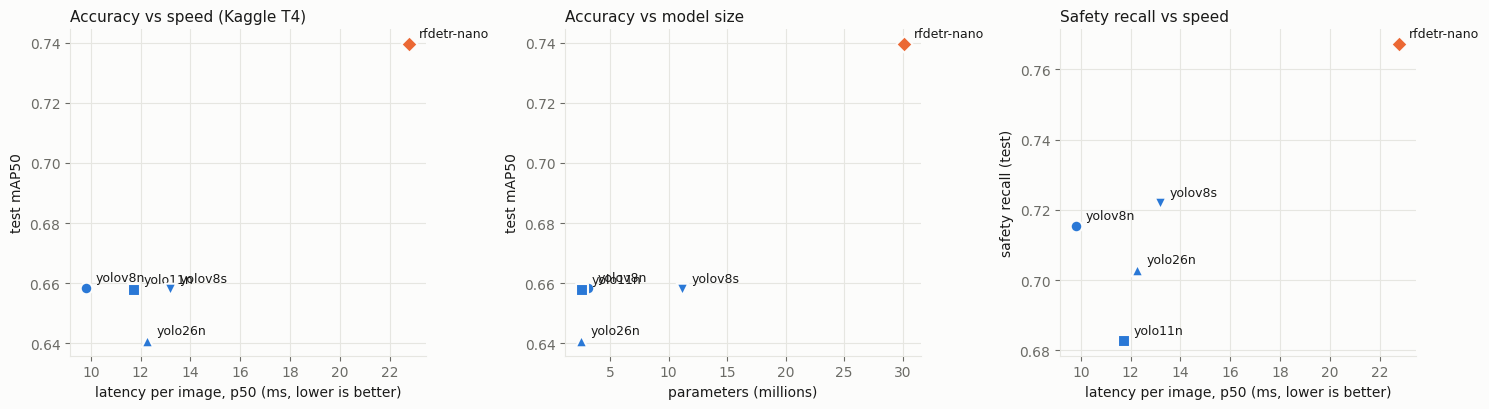

In [5]:
#@title 5. Accuracy vs speed and size
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
panels = [("p50 ms", "mAP50", "latency per image, p50 (ms, lower is better)", "test mAP50"),
          ("params (M)", "mAP50", "parameters (millions)", "test mAP50"),
          ("p50 ms", "safety recall", "latency per image, p50 (ms, lower is better)", "safety recall (test)")]
for ax, (xcol, ycol, xlabel, ylabel) in zip(axes, panels):
    for _, s in summary.iterrows():
        ax.scatter(s[xcol], s[ycol], s=70, marker=marker_of[s.model], color=color_of[s.model], edgecolor=SURFACE, linewidth=1.5, zorder=3)
        ax.annotate(s.model, (s[xcol], s[ycol]), xytext=(7, 5), textcoords="offset points", fontsize=9, color=INK)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
axes[0].set_title("Accuracy vs speed (Kaggle T4)", loc="left", fontsize=11)
axes[1].set_title("Accuracy vs model size", loc="left", fontsize=11)
axes[2].set_title("Safety recall vs speed", loc="left", fontsize=11)
fig.tight_layout(); save(fig, "accuracy_vs_speed"); plt.show()

Test boxes per class: {'Escalator': 158, 'People': 569, 'Pillar': 153, 'Stair': 288, 'Wet Floor Sign': 116}

Per-class AP50 on test:


,yolov8n,yolo11n,yolo26n,rfdetr-nano,yolov8s
Escalator,0.963,0.948,0.947,0.931,0.923
People,0.693,0.729,0.763,0.807,0.761
Pillar,0.238,0.196,0.194,0.351,0.181
Stair,0.775,0.757,0.741,0.797,0.749
Wet Floor Sign,0.624,0.658,0.559,0.811,0.676


Per-class recall at each model's alert threshold (share of real objects found):


,yolov8n,yolo11n,yolo26n,rfdetr-nano,yolov8s
Escalator,0.899,0.861,0.937,0.848,0.918
People,0.582,0.613,0.664,0.694,0.664
Pillar,0.170,0.163,0.190,0.294,0.190
Stair,0.688,0.670,0.646,0.729,0.688
Wet Floor Sign,0.560,0.517,0.526,0.724,0.560


Per-class precision at each model's alert threshold (share of alerts that were right):


,yolov8n,yolo11n,yolo26n,rfdetr-nano,yolov8s
Escalator,0.947,0.919,0.892,0.937,0.906
People,0.747,0.777,0.801,0.826,0.767
Pillar,0.542,0.439,0.527,0.523,0.433
Stair,0.818,0.801,0.845,0.857,0.822
Wet Floor Sign,0.903,0.968,0.984,0.988,0.956


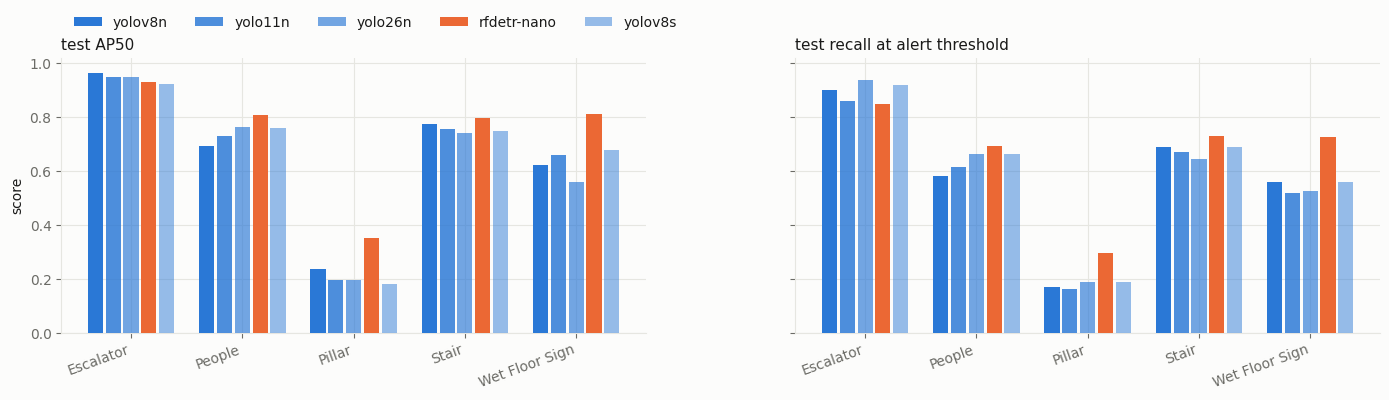

In [6]:
#@title 6. Per-class AP50 and recall
classes = runs[0]["dataset"]["classes"]
def per_class(key):
    df = pd.DataFrame({r["model_id"]: {c: (r["test"]["per_class"].get(c) or {}).get(key) for c in classes} for r in runs})
    return df.T.groupby(level=0, sort=False).mean().T
ap, rec, prec = per_class("ap50"), per_class("recall"), per_class("precision")
boxes = {c: (runs[0]["test"]["per_class"].get(c) or {}).get("boxes") for c in classes}
print("Test boxes per class:", boxes)
print("\nPer-class AP50 on test:")
display(ap.style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold"))
print("Per-class recall at each model's alert threshold (share of real objects found):")
display(rec.style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold"))
print("Per-class precision at each model's alert threshold (share of alerts that were right):")
display(prec.style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (df, label) in zip(axes, [(ap, "test AP50"), (rec, "test recall at alert threshold")]):
    w = 0.8 / max(1, len(df.columns)); x = np.arange(len(classes))
    for i, m in enumerate(df.columns):
        ax.bar(x + i * w - 0.4 + w / 2, df[m].fillna(0), width=w * 0.85, color=color_of[m],
               alpha=1 - 0.17 * (list(summary.model[summary.family == summary.set_index("model").family[m]]).index(m) % 4),
               label=m, zorder=3)
    ax.set_xticks(x); ax.set_xticklabels(classes, rotation=20, ha="right"); ax.set_ylim(0, 1.02); ax.set_title(label, loc="left", fontsize=11)
axes[0].set_ylabel("score")
axes[0].legend(frameon=False, ncol=len(ap.columns), loc="upper left", bbox_to_anchor=(0, 1.2))
fig.tight_layout(); save(fig, "per_class"); plt.show()

Share of test Stair, Escalator, Wet Floor Sign boxes that each model MISSES at its alert threshold (single frames):


,yolov8n,yolo11n,yolo26n,rfdetr-nano,yolov8s
Stair,31%,33%,35%,27%,31%
Escalator,10%,14%,6%,15%,8%
Wet Floor Sign,44%,48%,47%,28%,44%


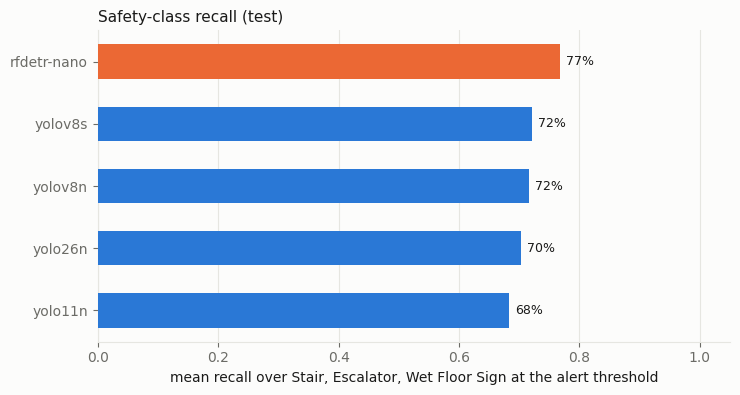

In [7]:
#@title 7. Safety classes: what does each model miss?
safety = list(runs[0].get("safety_classes") or ["Stair", "Escalator", "Wet Floor Sign"])
sr = rec.loc[[c for c in safety if c in rec.index]]
miss = (1 - sr)
print(f"Share of test {', '.join(safety)} boxes that each model MISSES at its alert threshold (single frames):")
display(miss.style.format("{:.0%}").highlight_min(axis=1, props="font-weight: bold"))

sf = summary.set_index("model")["safety recall"].dropna().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 0.55 * len(sf) + 1.3))
ax.barh(sf.index, sf.values, color=[color_of[m] for m in sf.index], height=0.55, zorder=3)
for y, v in enumerate(sf.values):
    ax.text(min(v + 0.01, 0.97), y, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlim(0, 1.05); ax.set_xlabel(f"mean recall over {', '.join(safety)} at the alert threshold")
ax.set_title("Safety-class recall (test)", loc="left", fontsize=11); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "safety_recall"); plt.show()

In [8]:
#@title 8. Which model for the glasses?
# Rule (state it in the report): keep models fast enough for real time, then rank by safety recall, then by mAP50.
LATENCY_BUDGET_MS = 33      # about 30 FPS on the Kaggle T4; the wearable will be slower, so smaller is safer
pick = summary.copy()
pick["real time"] = pick["p50 ms"] <= LATENCY_BUDGET_MS
pick = pick.sort_values(["real time", "safety recall", "mAP50"], ascending=[False, False, False])
display(pick[["model", "family", "safety recall", "mAP50", "mAP50-95", "p50 ms", "weights (MB)", "real time"]]
        .style.format({"safety recall": "{:.3f}", "mAP50": "{:.3f}", "mAP50-95": "{:.3f}", "p50 ms": "{:.1f}", "weights (MB)": "{:.1f}"})
        .hide(axis="index"))
top = pick.iloc[0]
print(f"Top under the rule: {top.model} (safety recall {top['safety recall']:.3f}, mAP50 {top.mAP50:.3f}, {top['p50 ms']:.1f} ms).")
if len(pick) > 1:
    second = pick.iloc[1]
    gap = top["safety recall"] - second["safety recall"]
    print(f"Runner-up: {second.model}. Safety-recall gap {gap:+.3f}"
          + (" — under about 0.02, so treat these two as tied with one seed." if abs(gap) < 0.02 else "."))
smallest = summary.loc[summary["weights (MB)"].idxmin()]
if smallest.model != top.model:
    print(f"Smallest model: {smallest.model} ({smallest['weights (MB)']:.1f} MB); "
          f"it gives up {top['safety recall'] - smallest['safety recall']:.3f} safety recall versus {top.model}.")
print(f"\nFigures and the summary table are saved in {FIG_DIR}/ for the report and poster.")

model,family,safety recall,mAP50,mAP50-95,p50 ms,weights (MB),real time
rfdetr-nano,RF-DETR,0.767,0.739,0.447,22.8,115.4,True
yolov8s,YOLO,0.722,0.658,0.404,13.2,21.5,True
yolov8n,YOLO,0.716,0.659,0.419,9.8,6.2,True
yolo26n,YOLO,0.703,0.641,0.405,12.2,5.2,True
yolo11n,YOLO,0.683,0.658,0.405,11.7,5.3,True


Top under the rule: rfdetr-nano (safety recall 0.767, mAP50 0.739, 22.8 ms).
Runner-up: yolov8s. Safety-recall gap +0.045.
Smallest model: yolo26n (5.2 MB); it gives up 0.064 safety recall versus rfdetr-nano.

Figures and the summary table are saved in /kaggle/working/figures/ for the report and poster.


## What to write in the report
- State once: dataset v4 (scene-based re-split, fingerprint from cell 2), five classes, seed 0, Kaggle T4. Cell 2 confirms these were identical for every run.
- State what differs on purpose: RF-DETR Nano and the YOLO models allow up to 100 epochs with early stopping, and uses a 384 px input against 640 px.
- Report **test mAP50, mAP50-95, safety recall, latency and size** per model (cell 3), plus the per-class table (cell 6).
- Name the weak class honestly (cell 6) and what each model misses on the safety classes (cell 7).
- Give the pick using the rule in cell 8, and say that latency on the glasses' processor still has to be measured.